# Error Analysis: Yoruba Tweet Sentiment Classification

This notebook studies where the deployed sentiment models fail. It reads the saved outputs of the main experiments notebook (data splits with their tweet-type flags, and the two models used in the web app) and does not retrain anything.

**Models analysed**
- Word + character TF-IDF logistic regression, diacritics removed (main model in the app)
- AfriBERTa fine-tuned on diacritics-removed text (second opinion in the app)

**Evaluation set:** test tweets that do not appear in training ("unseen", 3,938 tweets). This is the honest estimate, because tweets also found in training score about 0.2 macro-F1 higher.

**Questions**
1. Which classes are confused, and in which direction?
2. Does the error rate change with tweet type: code-mixed, containing negation, or carrying no tone marks?
3. Do the two models fail on the same tweets?
4. How confident are the models when they are wrong?
5. Which words push the main model towards each class?

**Inputs:** the checkpoints folder of the main notebook, attached as a Kaggle input.

In [5]:
import os, json, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
from IPython.display import display
from sklearn.metrics import f1_score, accuracy_score

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

### 1.2 Load the saved data and the deployed model
This notebook starts with none of the objects from the main experiments notebook, so this cell rebuilds only what the analysis needs: the test split with its tweet-type flags, and the logistic regression model exactly as it is deployed in the web app. The analysis uses test tweets that do not appear in training ("unseen"), the honest estimate. Tweets also found in training score about 0.2 macro-F1 higher and would hide the errors.

In [2]:
# Find the saved checkpoints from the finished notebook
READ_DIR = None
for root, _, files in os.walk("/kaggle/input/notebooks/divineifechukwude/sentiment-classification"):
    if "meta.json" in files and "step4_flags_test.parquet" in files:
        READ_DIR = Path(root)
        break
assert READ_DIR is not None, "Attach the finished notebook's output as an input."
print("Reading from:", READ_DIR)

meta = json.loads((READ_DIR / "meta.json").read_text(encoding="utf-8"))
label_names = meta["label_names"]
id2label = dict(enumerate(label_names))
print("Labels:", id2label)

frames = {s: pd.read_parquet(READ_DIR / f"step4_flags_{s}.parquet") for s in ["train", "validation", "test"]}
t = frames["test"]
EVAL_SETS = {
    "test_all":    t,
    "test_unseen": t[~t["seen_in_training"]],
    "test_seen":   t[t["seen_in_training"]],
}
print({k: len(v) for k, v in EVAL_SETS.items()})

def strip_marks(text):
    decomposed = unicodedata.normalize("NFD", text)
    kept = "".join(ch for ch in decomposed if not unicodedata.combining(ch))
    return unicodedata.normalize("NFC", kept)

APP_DIR = READ_DIR / "app_models"
lr_app = joblib.load(APP_DIR / "lr_diacritics_removed.joblib")
print("Model loaded:", type(lr_app).__name__)

Reading from: /kaggle/input/notebooks/divineifechukwude/sentiment-classification/checkpoints
Labels: {0: 'positive', 1: 'neutral', 2: 'negative'}
{'test_all': 4515, 'test_unseen': 3938, 'test_seen': 577}
Model loaded: Pipeline


### 1.3 Reproduce the deployed score and map the confusion
Before looking for causes, this cell checks that the loaded model gives the score reported in the main notebook (macro-F1 about 0.732 on unseen test tweets). If it does, every result below describes the deployed model. The confusion matrix then shows which classes get mixed up and in which direction.

In [3]:
ev = EVAL_SETS["test_unseen"]
print("Columns:", list(ev.columns))

X = ev["text_aligned"].map(strip_marks)
y = ev["label"].values
pred = lr_app.predict(X)

print("Macro-F1:", round(f1_score(y, pred, average="macro"), 3), "(expected about 0.732)")
cm = pd.crosstab(pd.Series(y).map(id2label), pd.Series(pred).map(id2label),
                 rownames=["true"], colnames=["predicted"])
display(cm)
display((cm.div(cm.sum(axis=1), axis=0) * 100).round(1))

Columns: ['tweet', 'label', 'label_name', 'text_norm', 'text_key', 'overlaps_train', 'nearest_train_sim', 'nearest_train_idx', 'match_letters_key', 'match_letters', 'match_letters_nohash_key', 'match_letters_nohash', 'seen_in_training', 'text_aligned', 'seen_v1', 'aligned_exact', 'aligned_sim', 'seen_aligned', 'mix_group', 'has_pidgin_cue', 'has_tone_mark', 'neg_marked', 'neg_unmarked', 'neg_english', 'neg_strong', 'neg_any']
Macro-F1: 0.732 (expected about 0.732)


predicted,negative,neutral,positive
true,,,
negative,596,179,94
neutral,206,1054,162
positive,165,195,1287


predicted,negative,neutral,positive
true,,,
negative,68.6,20.6,10.8
neutral,14.5,74.1,11.4
positive,10.0,11.8,78.1


**Interpretation.** The loaded model reproduces the reported macro-F1 of 0.732 on the 3,938 unseen test tweets (accuracy 74.6%, 1,001 errors).

- Neutral is at the centre of the confusion. 742 of the 1,001 errors (74%) have neutral as the true label or as the prediction. Separating "has sentiment" from "has none" is harder for the model than separating positive from negative.
- Direct flips between positive and negative are the minority: 259 errors (26%), made up of 165 positive tweets called negative and 94 negative tweets called positive.
- Negative is the weakest class. Recall is 68.6%, against 74.1% for neutral and 78.1% for positive. Precision is also lowest for negative (61.6%), because the model predicts negative 967 times while 869 tweets are truly negative, an over-prediction of about 11%.
- The three largest error cells are neutral called negative (206), positive called neutral (195) and negative called neutral (179).

These counts describe where the model fails but not why. The next cell checks whether the error rate depends on the kind of tweet.

### 1.4 Error rate by tweet type
The saved flags mark each test tweet as code-mixed or not, as containing negation or not, and as carrying tone marks or not. If the error rate differs between groups, that points to a cause. Small groups give noisy rates, so each rate comes with a 95% bootstrap interval, and a difference is only claimed when it clearly exceeds those intervals.

In [4]:
# Error rate by tweet type, with bootstrap 95% intervals
ev = EVAL_SETS["test_unseen"].copy()
ev["pred_lr"] = pred
ev["wrong_lr"] = (ev["pred_lr"] != ev["label"]).astype(int)

rng = np.random.default_rng(0)

def err_ci(wrong, n_boot=1000):
    w = np.asarray(wrong)
    boots = [w[rng.integers(0, len(w), len(w))].mean() for _ in range(n_boot)]
    return np.percentile(boots, [2.5, 97.5])

def group_table(df, col):
    rows = []
    for g, d in df.groupby(col):
        lo, hi = err_ci(d["wrong_lr"])
        rows.append({"group": g, "n": len(d),
                     "error_rate": round(d["wrong_lr"].mean(), 3),
                     "ci_low": round(lo, 3), "ci_high": round(hi, 3),
                     "macro_F1": round(f1_score(d["label"], d["pred_lr"], average="macro"), 3)})
    return pd.DataFrame(rows).set_index("group")

print("Overall error rate:", round(ev["wrong_lr"].mean(), 3))
for col in ["mix_group", "has_tone_mark", "neg_strong"]:
    print("\n" + col)
    display(group_table(ev, col))

Overall error rate: 0.254

mix_group


,n,error_rate,ci_low,ci_high,macro_F1
group,,,,,
english only,22,0.409,0.227,0.636,0.518
mixed,359,0.315,0.265,0.365,0.677
no English cue,3557,0.247,0.233,0.260,0.739



has_tone_mark


,n,error_rate,ci_low,ci_high,macro_F1
group,,,,,
False,808,0.265,0.234,0.297,0.712
True,3130,0.251,0.236,0.266,0.730



neg_strong


,n,error_rate,ci_low,ci_high,macro_F1
group,,,,,
False,3006,0.238,0.223,0.253,0.744
True,932,0.307,0.280,0.337,0.684


**Interpretation.** The overall error rate is 25.4% (1,001 of 3,938 unseen test tweets).

- **Negation is the clearest effect.** Tweets with strong negation cues (932 tweets, 24% of the set) have an error rate of 30.7% (95% interval 28.0 to 33.7), against 23.8% (22.3 to 25.3) for the rest. The intervals do not overlap, and macro-F1 falls from 0.744 to 0.684. Against the 23.8% baseline this group has about 64 more errors than expected, around 6% of all errors.
- **Code-mixing shows a smaller gap.** Mixed tweets (359) have an error rate of 31.5% (26.5 to 36.5), against 24.7% (23.3 to 26.0) for tweets with no English cue. The gap is about 7 points, but the intervals nearly touch, and the main experiments found that the code-mixing penalty appeared on the test split but not on validation. It is reported here as suggestive and not as established. It accounts for roughly 24 extra errors.
- **English-only tweets (22) are too few to say anything.** The interval (22.7 to 63.6%) spans nearly everything.
- **Missing tone marks do not hurt.** Tweets without tone marks (808) have an error rate of 26.5% (23.4 to 29.7), against 25.1% (23.6 to 26.6) for tweets with them. The intervals overlap and the macro-F1 values (0.712 and 0.730) are within the noise level of about 0.015. This matches the earlier result that removing diacritics before prediction makes the model robust to them.

The negation and code-mixing flags are proxies based on word lists, so they miss some cases and the true effects may be larger. And each effect explains only a small share of the errors: most of the 1,001 errors occur in tweets with none of these features, so the three problems studied are not the main source of error.

The next question is whether the second model makes the same mistakes.
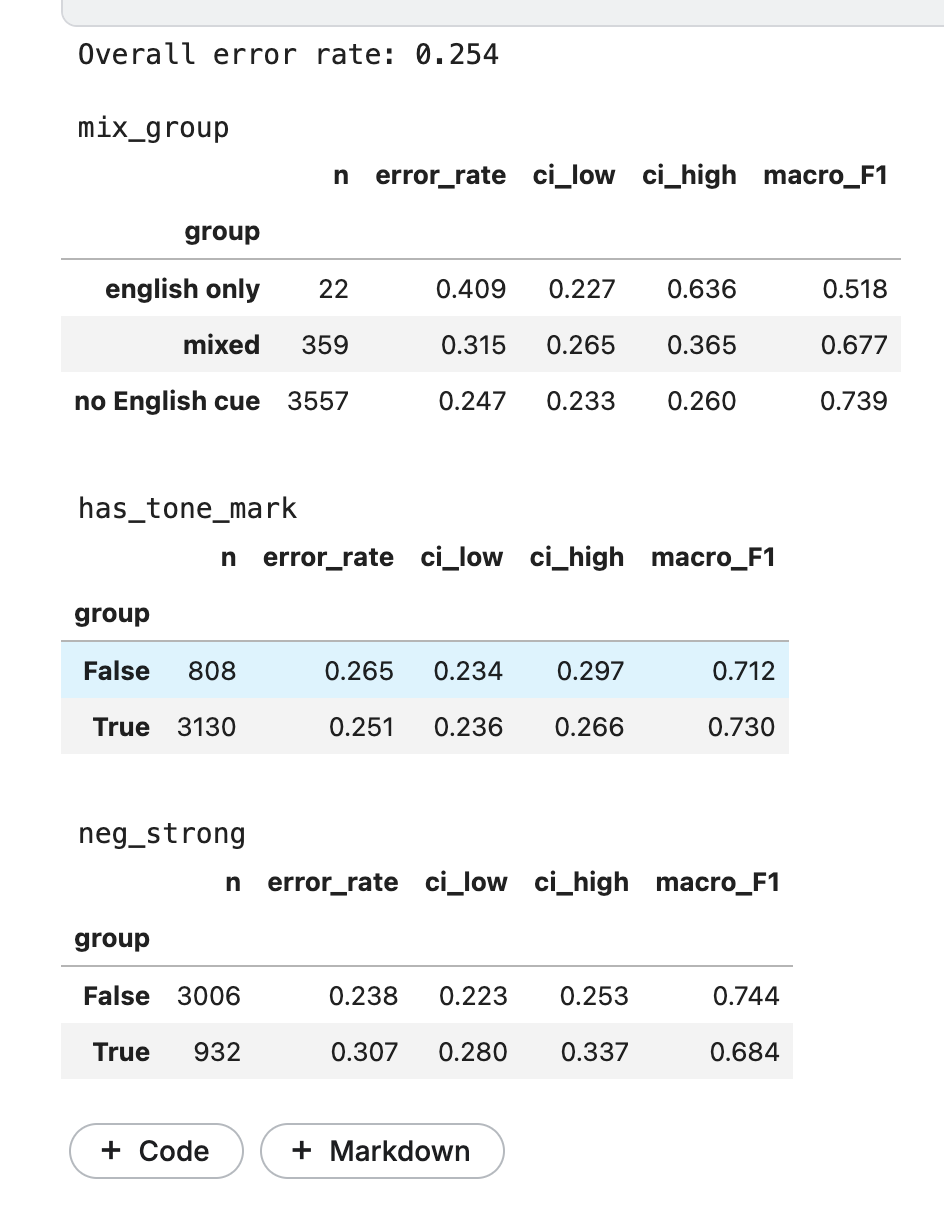

### 1.5 Predictions from the second model
To compare the two models, this cell runs the fine-tuned AfriBERTa (diacritics removed, the second opinion in the web app) over the same unseen test tweets and stores its predictions and class probabilities next to those of the logistic regression. The check against its reported macro-F1 (about 0.726) confirms the model loaded correctly before anything is compared.

In [7]:
# AfriBERTa predictions and probabilities on the same unseen test tweets
device = "cuda" if torch.cuda.is_available() else "cpu"
nn_dir = APP_DIR / "afriberta_diacritics_removed"
tok = AutoTokenizer.from_pretrained(nn_dir)
nn_model = AutoModelForSequenceClassification.from_pretrained(nn_dir).to(device).eval()

texts = ev["text_aligned"].map(strip_marks).tolist()
probs = []
with torch.no_grad():
    for i in range(0, len(texts), 64):
        enc = tok(texts[i:i + 64], return_tensors="pt", truncation=True,
                  max_length=128, padding=True).to(device)
        probs.append(torch.softmax(nn_model(**enc).logits, dim=-1).cpu().numpy())
nn_probs = np.vstack(probs)

ev["pred_nn"] = nn_probs.argmax(axis=1)
ev["conf_nn"] = nn_probs.max(axis=1)
ev["wrong_nn"] = (ev["pred_nn"] != ev["label"]).astype(int)

lr_probs = lr_app.predict_proba(ev["text_aligned"].map(strip_marks))
ev["conf_lr"] = lr_probs.max(axis=1)

print("Device:", device)
print("AfriBERTa macro-F1:", round(f1_score(ev["label"], ev["pred_nn"], average="macro"), 3), "(expected about 0.726)")
print("Both wrong:", int(((ev.wrong_lr == 1) & (ev.wrong_nn == 1)).sum()),
      "| only LR wrong:", int(((ev.wrong_lr == 1) & (ev.wrong_nn == 0)).sum()),
      "| only AfriBERTa wrong:", int(((ev.wrong_lr == 0) & (ev.wrong_nn == 1)).sum()))

Loading weights:   0%|          | 0/137 [00:00<?, ?it/s]

Device: cpu
AfriBERTa macro-F1: 0.726 (expected about 0.726)
Both wrong: 657 | only LR wrong: 344 | only AfriBERTa wrong: 347


**Interpretation.** The saved AfriBERTa model reproduces its reported macro-F1 of 0.726, so the comparison below uses the deployed second model.

The two models make almost the same number of errors: 1,001 for logistic regression and 1,004 for AfriBERTa. But they make them on largely the same tweets.

- Both wrong: 657 tweets. Only logistic regression wrong: 344. Only AfriBERTa wrong: 347.
- 66% of each model's errors are shared (657 of 1,001 and 657 of 1,004).
- If the two models erred independently at their own rates (25.4% and 25.5%), only about 255 tweets would be wrong for both. The observed 657 is about 2.6 times that.

This means the errors depend mostly on the tweets, not on the model family. A word-and-character model and a pretrained transformer fail together on 657 tweets, which suggests the cause sits in the data: ambiguous or context-dependent tweets, inconsistent labels, or both. Labels that are wrong would produce exactly this pattern, because both models learn from the same labels. This analysis cannot separate hard tweets from wrong labels, since a manual label check was not completed, and the report should say so.

It also limits what combining the models can achieve. Even a perfect rule for choosing between them could only fix the 691 tweets where they disagree on correctness, and the 657 shared errors would remain.

### 1.6 Agreement and confidence
The web app shows both models side by side, so it matters whether agreement means anything. This cell measures accuracy when the two models agree versus when they disagree. It also checks how confident each model is when it is wrong, by comparing stated confidence with actual accuracy in confidence bins. If confidence tracks accuracy, a user can read the probabilities in the app. If not, the app should warn that high confidence is not a guarantee.

In [8]:
# Accuracy by agreement, and confidence versus accuracy
ev["agree"] = ev["pred_lr"] == ev["pred_nn"]
agree_tab = ev.groupby("agree").agg(
    n=("label", "size"),
    acc_lr=("wrong_lr", lambda w: 1 - w.mean()),
    acc_nn=("wrong_nn", lambda w: 1 - w.mean()),
).round(3)
agree_tab["share_%"] = (agree_tab["n"] / len(ev) * 100).round(1)
print("Models agree (True) or disagree (False)")
display(agree_tab)

bins = [0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]

def conf_table(conf, wrong, name):
    d = pd.DataFrame({"conf": conf, "right": 1 - wrong})
    d["bin"] = pd.cut(d["conf"], bins, right=False)
    g = d.groupby("bin", observed=True).agg(n=("right", "size"),
                                            mean_conf=("conf", "mean"),
                                            accuracy=("right", "mean")).round(3)
    ece = (g["n"] / g["n"].sum() * (g["accuracy"] - g["mean_conf"]).abs()).sum()
    print(f"\n{name}: expected calibration error = {ece:.3f}")
    display(g)

conf_table(ev["conf_lr"].values, ev["wrong_lr"].values, "Logistic regression")
conf_table(ev["conf_nn"].values, ev["wrong_nn"].values, "AfriBERTa")

Models agree (True) or disagree (False)


,n,acc_lr,acc_nn,share_%
agree,,,,
False,817,0.425,0.421,20.7
True,3121,0.830,0.830,79.3



Logistic regression: expected calibration error = 0.014


,n,mean_conf,accuracy
bin,,,
"[0.0, 0.5)",487,0.447,0.446
"[0.5, 0.6)",578,0.550,0.512
"[0.6, 0.7)",571,0.650,0.650
"[0.7, 0.8)",571,0.750,0.778
"[0.8, 0.9)",665,0.852,0.866
"[0.9, 1.0)",1066,0.961,0.969



AfriBERTa: expected calibration error = 0.210


,n,mean_conf,accuracy
bin,,,
"[0.0, 0.5)",16,0.460,0.625
"[0.5, 0.6)",108,0.545,0.491
"[0.6, 0.7)",106,0.649,0.396
"[0.7, 0.8)",132,0.751,0.485
"[0.8, 0.9)",189,0.853,0.444
"[0.9, 1.0)",3387,0.992,0.792


**Interpretation.**

*Agreement.* The two models agree on 79.3% of the unseen test tweets (3,121) and disagree on 20.7% (817).
- When they agree, the shared prediction is right 83.0% of the time.
- When they disagree, each model is right only about 42% of the time, and about 126 of these tweets are wrong for both, with different labels each.
- The error rate of the logistic regression is 17.0% when the models agree and 57.5% when they disagree, 3.4 times higher. The disagreement set holds 470 of its 1,001 errors (47%) in a fifth of the tweets. So disagreement is a useful warning, but it cannot catch the other 531 errors, which both models make together and which look like confident correct answers.

*Confidence.* The two models differ sharply.
- The logistic regression is well calibrated: expected calibration error is 0.014. In the top bin (confidence 0.9 and above, 1,066 tweets) the mean confidence is 0.961 and the accuracy 0.969, and the other bins follow the same pattern. Its probabilities can be read as probabilities.
- AfriBERTa is strongly overconfident: expected calibration error is 0.210. 3,387 of the 3,938 tweets (86%) receive confidence of 0.9 or more (mean 0.992), but only 79.2% of them are right. In the 0.6 to 0.9 range (427 tweets) its accuracy is between 0.40 and 0.49 although its confidence is between 0.65 and 0.85. The lowest bin has only 16 tweets and is not interpreted. Overconfidence of this kind is common in fine-tuned transformers that fit the training data almost perfectly, but this was not tested here.

*Consequence for the web app.* The logistic regression percentages are meaningful, and AfriBERTa's are not. The app should present AfriBERTa as a second label, and its percentage should not be read as a measure of certainty. The "models disagree" warning is supported by the data.

### 1.7 What the main model has learned
The logistic regression is a linear model, so its weights show which words push a tweet towards each class. Listing the strongest words per class shows whether the model relies on real sentiment words, or on topic words and artefacts of the data, and gives a concrete basis for the errors seen above.

In [9]:
# Strongest words per class in the logistic regression (word features only)
feats = lr_app.named_steps["features"]
clf = lr_app.named_steps["clf"]
print("Feature blocks:", [name for name, _ in feats.transformer_list])
print("Class order:", clf.classes_, [id2label[c] for c in clf.classes_])

names = []
for name, tr in feats.transformer_list:
    names += [f"{name}|{n}" for n in tr.get_feature_names_out()]
names = np.array(names)
assert len(names) == clf.coef_.shape[1], "feature count mismatch"

is_word = np.array([n.startswith(feats.transformer_list[0][0] + "|") for n in names])
print("Word-feature share:", round(is_word.mean(), 3), "| first block:", feats.transformer_list[0][0])

rows = {}
for i, c in enumerate(clf.classes_):
    w = np.where(is_word, clf.coef_[i], -np.inf)
    top = np.argsort(w)[::-1][:15]
    rows[id2label[c]] = [names[j].split("|", 1)[1] for j in top]
display(pd.DataFrame(rows))

Feature blocks: ['word', 'char']
Class order: [0 1 2] ['positive', 'neutral', 'negative']
Word-feature share: 0.391 | first block: word


,positive,neutral,negative
0,e ku,ki ni,ole
1,ire,ti a,pa
2,olorun,ma n,iku
3,e,ni a,iro
4,eku,re e,ko
5,rere,idi,won
6,o ni,pe awon,dun ni
7,wa,jo,iwa
8,dupe,a oo,ma wa
9,feran,won ma,e gbadun


**Interpretation.** The table lists the highest-weight word features of the logistic regression (single words and word pairs, written without tone marks and underdots because the model reads diacritic-free text). The glosses below are approximate, since removing diacritics merges words that differ only by tone, and they should be checked by a Yoruba speaker before being quoted.

- **Positive** is led by greetings, blessings and thanks: "e ku" (a greeting), "ire" (good fortune), "olorun" (God), "rere" (good), "dupe" (thanks), "feran" (love), "dara" (good). The class is learned largely from formulaic expressions of greeting, prayer and gratitude.
- **Negative** is led by words for wrongdoing, conflict and denial: "ole" (thief), "pa" (kill), "iku" (death), "iro" (lie), "ija" (fight), "were" (mad), "yeye" (nonsense), together with "ko", which probably includes the negation marker. This is consistent with the earlier negation result, because a word like "ko" pushes a tweet towards negative whenever it appears, and many negated tweets are not negative.
- **Neutral** is led mostly by grammatical and reporting patterns, not by content words: "ki ni" (what is), "pe awon" and "mo wipe" (that...), "ti a", "ni a", "lo si", plus "aworan" (picture). The neutral class is recognised by the absence of sentiment words and by question and reporting phrasing. This helps explain why neutral sits at the centre of the confusion matrix: a tweet with no clear sentiment word, or with an ambiguous one, can slide between neutral and either polar class.

Weights show association in the training data, not causation, and a word-level model has no way to tell "not good" from "good" beyond what the word pairs capture. The next cell looks at the tweets where both models are most confidently wrong.

### 1.8 Confident errors shared by both models
Tweets that both models get wrong while each is at least 90% confident are the most informative errors. A model that is unsure may simply lack evidence, but two different models that are both sure and both wrong point to either an ambiguous tweet or a questionable label. This cell counts them and prints a random sample for reading.

In [10]:
# Tweets where both models are wrong and both are at least 90% confident
conf_wrong = ev[(ev.wrong_lr == 1) & (ev.wrong_nn == 1) & (ev.conf_lr >= 0.9) & (ev.conf_nn >= 0.9)]
print("Confident shared errors:", len(conf_wrong),
      "| share of all LR errors:", round(len(conf_wrong) / ev.wrong_lr.sum() * 100, 1), "%")
print("\nTrue label -> predicted (LR), counts:")
display(pd.crosstab(conf_wrong["label"].map(id2label), conf_wrong["pred_lr"].map(id2label),
                    rownames=["true"], colnames=["predicted"]))

pd.set_option("display.max_colwidth", 220)
sample = conf_wrong.sample(min(20, len(conf_wrong)), random_state=0)
out = sample[["tweet", "label", "pred_lr", "pred_nn"]].copy()
for c in ["label", "pred_lr", "pred_nn"]:
    out[c] = out[c].map(id2label)
display(out.reset_index(drop=True))

Confident shared errors: 28 | share of all LR errors: 2.8 %

True label -> predicted (LR), counts:


predicted,negative,neutral,positive
true,,,
negative,0,6,3
neutral,4,0,5
positive,4,6,0


,tweet,label,pred_lr,pred_nn
0,ogun ti se egbe okunkun boko haramuuu ti surendaaaa o agbenuso fun awon omo ogun nijeria ogagun lo so be ni ilu abuja,positive,negative,negative
1,ìwà wa dúdú bí ẹranko igbó ọ̀bọ ni adú a ò yàtọ̀ sí ẹranko ìgbẹ́,negative,neutral,neutral
2,àkísà lògbà rí jàlàbíyà ni láyé ìgbà kan àmọ́ àbáyà tún ni wọ́n ń gba wèrèe rẹ̀ báyìí gbogbo rẹ̀ ṣá ló ń yà,neutral,negative,negative
3,e fun wa je oju aanu rt adìẹ díndín ti wọkùn adìẹ àdíngbẹ aláta rodo,neutral,negative,negative
4,nínú àwọn ìlú ilẹ̀ yoòbá tí ó jẹ́ igbó kìjikìji ìpínlẹ̀ ògùn jẹ́ ọkàn ìdí kan sì nìyí tí òrìṣà òṣóòsì fi gbayì ńbẹ,positive,neutral,neutral
5,ẹ má fi bẹ́ẹ̀ gbógun ti ọtí ògógóró torí ó ní ṣe ńnú ìtàn ilẹ̀ wa bí a bá ń sọ̀rọ̀ ẹmu a ó sọ̀rọ̀ ògógóró,neutral,negative,negative
6,ifisipo pelu etan ti ko fara pamo ṣé ìdìbò ni tòní àbí ìfisípò,negative,neutral,neutral
7,mà á rọ̀ wá ká máa lójúmọ́ ká ṣeé ní,neutral,positive,positive
8,τ̲̅ơ̴̴̴̴̴̴͡ ba jumilo o ju olorun lo ma ale mo kayode mi,negative,positive,positive
9,ìwọ ganan ni ìṣòro ìlọsíwájú èdè àṣà àti ìṣe èdè yorùbá bẹ́ẹ̀ ni mo sọ ìwọ tí ò ń ka túwìtì mi yìí púpọ̀ ńbẹ̀ jẹ́ tìrẹ,negative,positive,positive


**Interpretation.** Only 28 tweets are wrong for both models while both are at least 90% confident. That is 2.8% of the logistic regression's 1,001 errors. Confident, shared errors are therefore rare, and most errors happen where at least one model was unsure.

- The 28 are spread across every direction (negative called neutral 6, negative called positive 3, neutral called negative 4, neutral called positive 5, positive called negative 4, positive called neutral 6). No single kind of mistake dominates.
- This does not support the idea that the shared errors are mostly clear label mistakes that both models see through. A clearly mislabelled tweet would tend to produce a confident disagreement with the label, and these are few. Most shared errors look more like genuinely ambiguous tweets.
- The AfriBERTa side of this filter is weak, because that model is at least 90% confident on 86% of all tweets. The logistic regression's confidence is the real constraint, and that model is well calibrated.

In the printed sample, two patterns stand out (my reading of the Yoruba, to be checked by a speaker).
- *Words with strong sentiment weights appear in tweets labelled otherwise.* Tweets containing "olorun" (God), "eku" or "ku" (greeting) are called positive although labelled negative, and tweets containing "ole" (thief) or "were" (mad) are called negative although labelled neutral. This matches the word weights in 1.7: the model follows the word, not how the word is used.
- *Descriptive, proverbial or religious tweets with implicit praise or criticism.* Several tweets about Yoruba towns, culture or proverbs are labelled positive or negative, but both models say neutral, because the text has no explicit sentiment word.

Only 20 tweets were printed and none was verified by a second reader, so these patterns are illustrations and not measured proportions.

### 1.9 Summary of findings
1. On 3,938 unseen test tweets, the deployed logistic regression has macro-F1 0.732 and 1,001 errors; AfriBERTa has 0.726 and 1,004 errors.
2. Neutral is at the centre of the confusion: 74% of errors involve it. Negative is the weakest class (recall 68.6%, precision 61.6%) and is over-predicted by about 11%.
3. Negation is the clearest tweet-type effect (error rate 30.7% against 23.8%). The code-mixing gap (31.5% against 24.7%) is suggestive but did not replicate across splits in earlier experiments. Missing tone marks cause no penalty.
4. The two models share 66% of their errors, about 2.6 times what independent errors would give. Most errors therefore come from the tweets, not the model family, and combining the two models cannot fix them.
5. Model agreement is informative: 83.0% accuracy when they agree, about 42% when they disagree.
6. The logistic regression is well calibrated (ECE 0.014). AfriBERTa is strongly overconfident (ECE 0.210), so its probabilities should not be read as certainty.
7. The logistic regression relies on lexical cues (greetings, blessings and thanks for positive; wrongdoing and conflict words for negative; question and reporting phrases for neutral), which explains errors where those words are used differently.
8. Confident shared errors are rare (28), so most errors look like ambiguous tweets and not clear label mistakes. A manual label check was not completed, so this could not be tested directly.

In [11]:
# Save the per-tweet predictions and the group tables, with download links
import base64
from IPython.display import HTML

out_cols = ["tweet", "label", "pred_lr", "pred_nn", "conf_lr", "conf_nn", "wrong_lr", "wrong_nn",
            "mix_group", "has_tone_mark", "neg_strong"]
ev[out_cols].to_csv("error_analysis_predictions.csv", index=False)

groups = pd.concat({c: group_table(ev, c) for c in ["mix_group", "has_tone_mark", "neg_strong"]})
groups.to_csv("error_rate_by_group.csv")

def link(path):
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    return f'<a download="{path}" href="data:text/csv;base64,{b64}">Download {path}</a><br>'

display(HTML(link("error_analysis_predictions.csv") + link("error_rate_by_group.csv")))